In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a new method for learning deep neur...,0.3177,0.0800,0.1661,0.8682,0.8136,0.8400,2,7,8,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,"In this paper, we propose a novel 3D convoluti...",0.3541,0.0865,0.1914,0.8422,0.8061,0.8238,3,4,5,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We present a new approach to the specification...,0.2055,0.0621,0.1301,0.8001,0.8486,0.8236,3,2,4,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


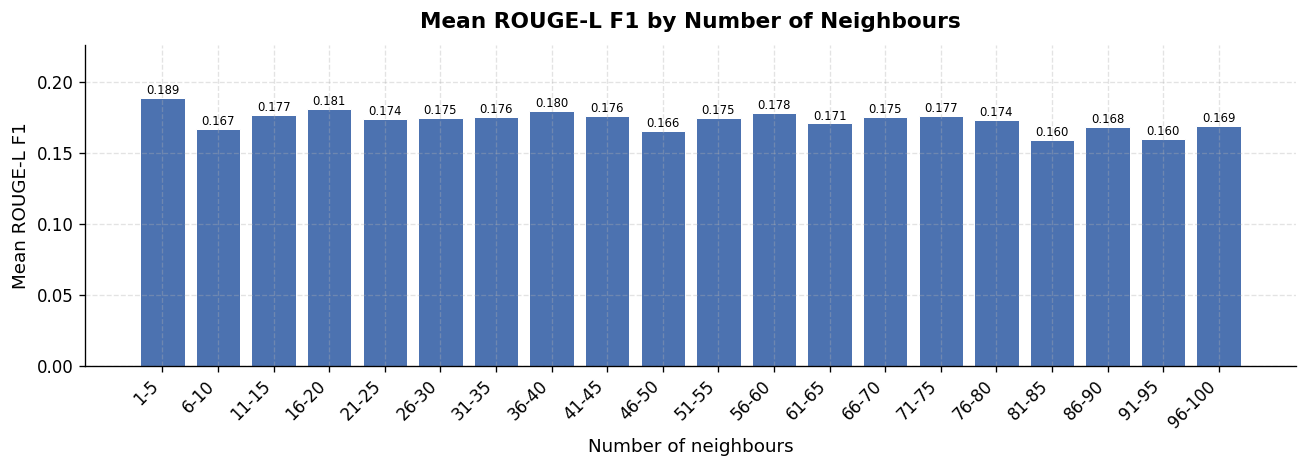

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

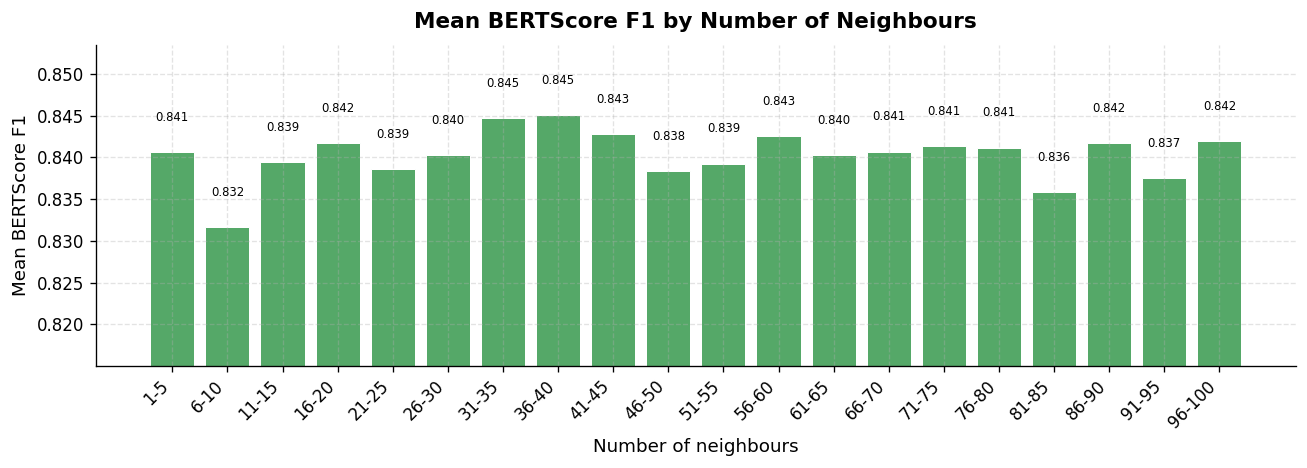

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

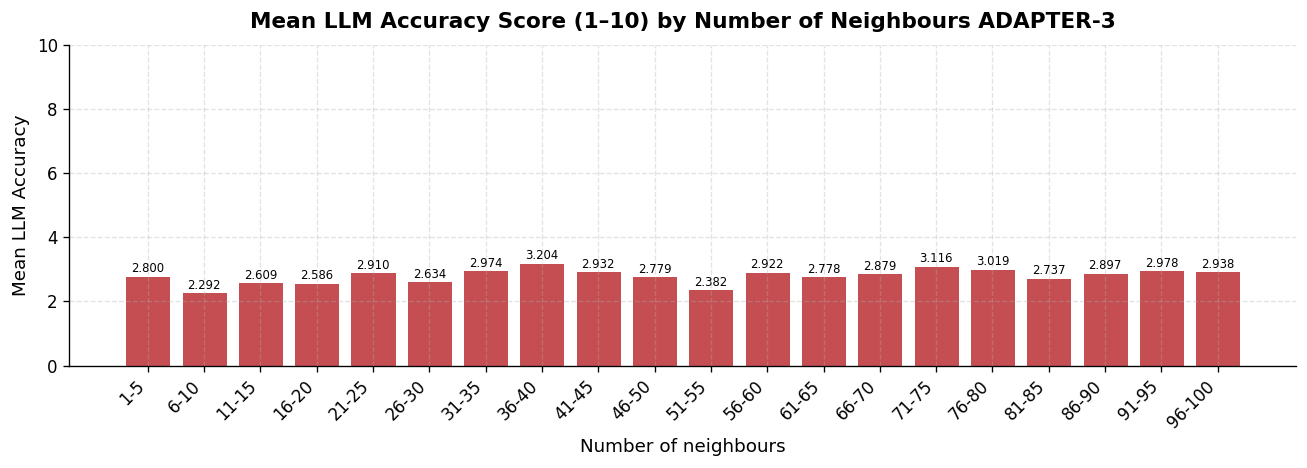

2.817989417989418
3.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

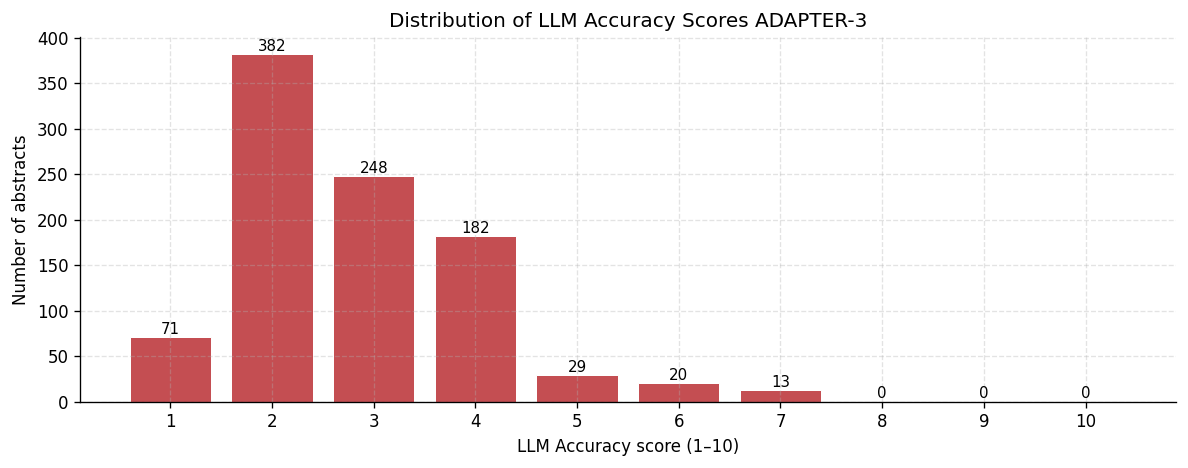

llm_accuracy
1      71
2     382
3     248
4     182
5      29
6      20
7      13
8       0
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

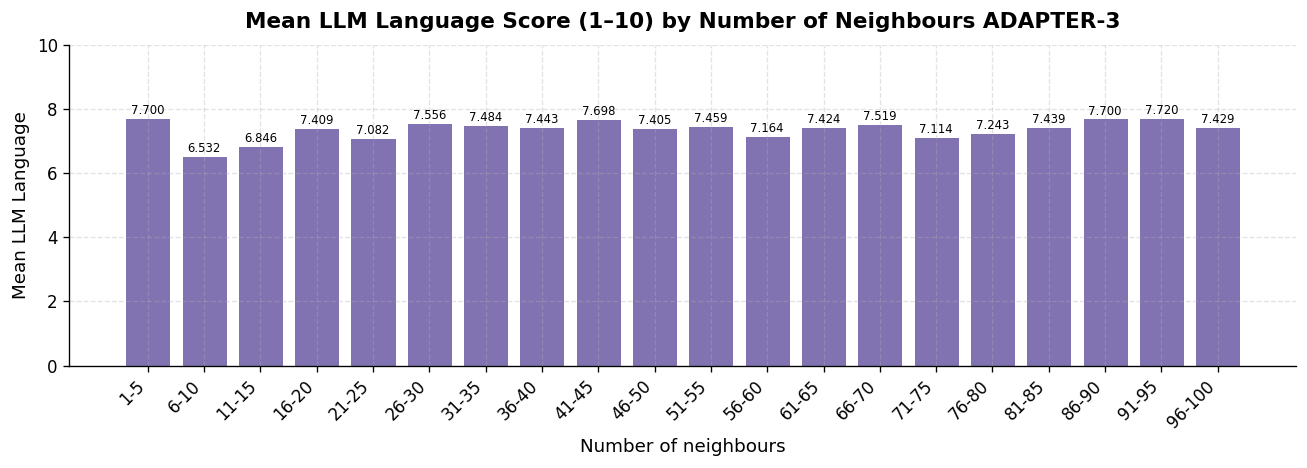

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

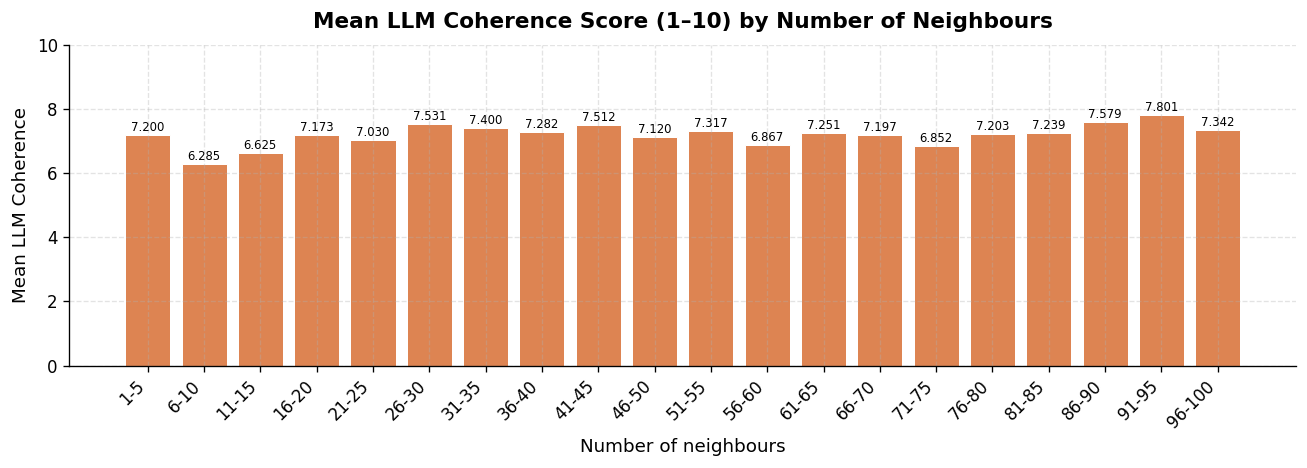

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

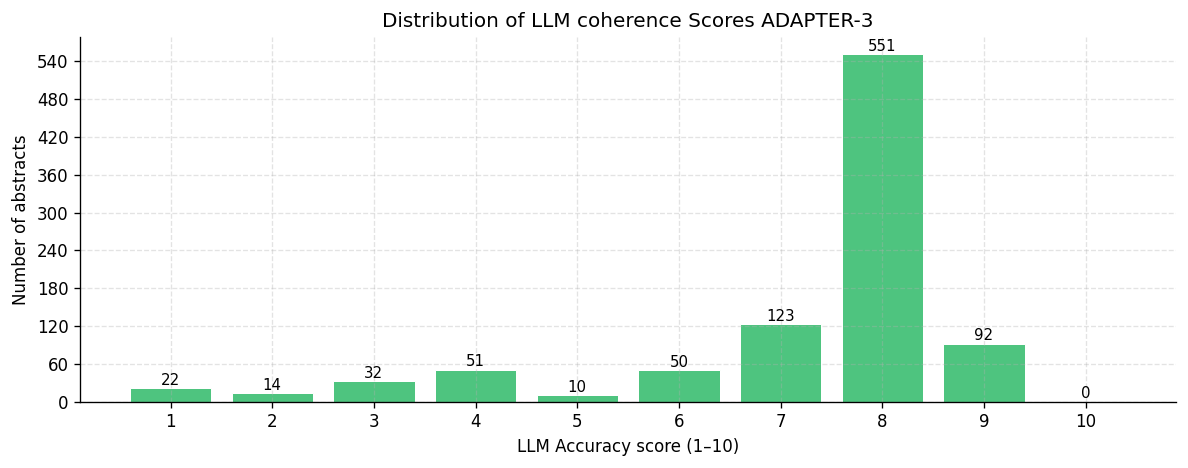

llm_coherence
1      22
2      14
3      32
4      51
5      10
6      50
7     123
8     551
9      92
10      0
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 36 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      2.8180
Mean llm_accuracy (excluding 1,2): 2.8537


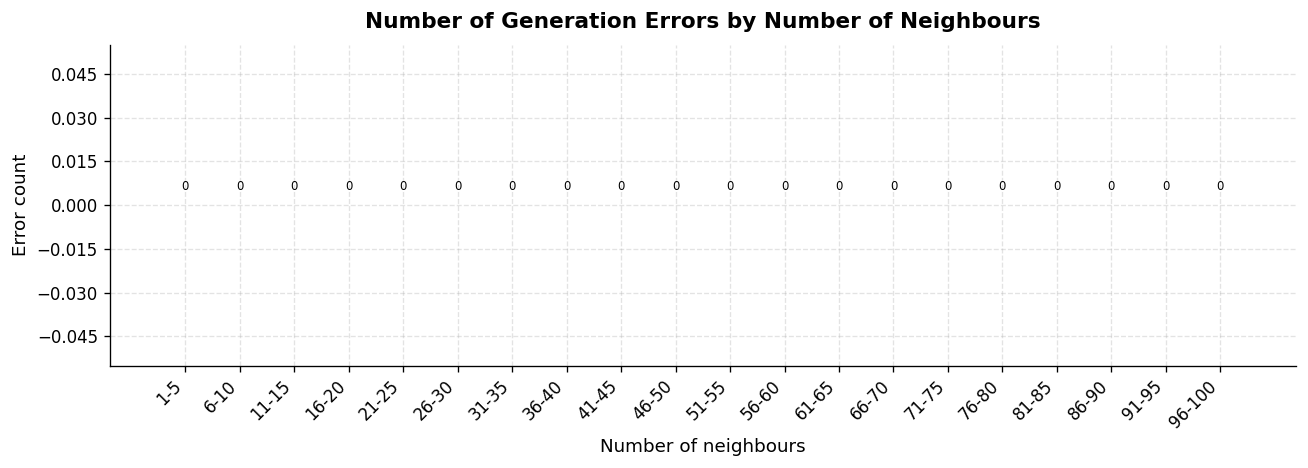

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_7499/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,88516,"In class-incremental learning, a model learns continuously from a sequential data stream in which new classes occur. Existing methods often rely on static architectures that are manually crafted. These methods can be prone to capacity saturation because a neural network's ability to generalize to new concepts is limited by its fixed capacity. To understand how to expand a continual learner, we focus on the neural architecture design problem in the context of class-incremental learning: at each time step, the learner must optimize its performance on all classes observed so far by selecting the most competitive neural architecture. To tackle this problem, we propose Continual Neural Architecture Search (CNAS): an autoML approach that takes advantage of the sequential nature of class-incremental learning to efficiently and adaptively identify strong architectures in a continual learning setting. We employ a task network to perform the classification task and a reinforcement learning agent as the meta-controller for architecture search. In addition, we apply network transformations to transfer weights from previous learning step and to reduce the size of the architecture search space, thus saving a large amount of computational resources. We evaluate CNAS on the CIFAR-100 dataset under varied incremental learning scenarios with limited computational power (1 GPU). Experimental results demonstrate that CNAS outperforms architectures that are optimized for the entire dataset. In addition, CNAS is at least an order of magnitude more efficient than naively using existing autoML methods.","We propose a novel approach to continual learning, where a neural network is trained on a sequence of tasks, and is able to learn new tasks without forgetting previous ones. Our approach is based on the observation that the gradient of the loss function with respect to the parameters of the network is a linear function of the parameters. We use this observation to derive a novel algorithm for continual learning, which we call the Linear-Linear (LL) algorithm. We show that the LL algorithm is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and that it is able to learn a sequence of tasks with a single pass through the data, and",1
1,162201,"This paper introduces and evaluates the GestureKeeper, a robust hand-gesture recognition system based on a wearable inertial measurements unit (IMU). The identification of the time windows where the gestures occur, without relying on an explicit user action or a special gesture marker, is a very challenging task. To address this problem, GestureKeeper identifies the start of a gesture by exploiting the underlying dynamics of the associated time series using a recurrence quantification analysis (RQA). RQA is a powerful method for nonlinear time-series analysis, which enables the detection of critical transitions in the system's dynamical behavior. Most importantly, it does not make any assumption about the underlying distribution or model that governs the data. Having estimated the 

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_7499/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,149639,"Given $N$ instances $(X_1,t_1),\ldots,(X_N,t_N)$ of Subset Sum, the AND Subset Sum problem asks to determine whether all of these instances are yes-instances; that is, whether each set of integers $X_i$ has a subset that sums up to the target integer $t_i$. We prove that this problem cannot be solved in $\tilde{O}((N \cdot t_{max})^{1-\epsilon})$ time, for $t_{max}=\max_i t_i$ and any $\epsilon > 0$, assuming the $\forall \exists$ Strong Exponential Time Hypothesis ($\forall \exists$-SETH). We then use this result to exclude $\tilde{O}(n+P_{max} \cdot n^{1-\epsilon})$-time algorithms for several scheduling problems on $n$ jobs with maximum processing time $P_{max}$, based on $\forall \exists$-SETH. These include classical problems such as $1||\sum w_jU_j$, the problem of minimizing the total weight of tardy jobs on a single machine, and $P_2||\sum U_j$, the problem of minimizing the number of tardy jobs on two identical parallel machines.","We study the problem of finding a minimum weight codeword in a linear code. This problem is NP-hard in general, but in this paper, we consider the case that the code is given in a special form. Namely, we consider the case that the code is a binary Reed-Muller code of order m. We show that the problem of finding a minimum weight codeword in this case, called the minimum distance problem, can be solved in time 2^ O(n^ 1-1/(m+1) ) , where n is the length of the code and m is a constant. This is a huge improvement over the brute-force approach which runs in time 2^n. #R##N#We also show that the problem of finding a minimum distance codeword in a Reed-Muller code of order m can be reduced to solving O(n^ 1-1/(m+1) ) instances of the minimum distance problem for Reed-Muller codes of order m-1. This gives a recursive algorithm for solving the minimum distance problem for Reed-Muller codes of order m. We also show that the same approach can be used to solve the minimum distance problem for Reed-Muller-type codes of order m, which include the Reed-Muller codes and the Reed-Solomon codes as special cases.",1
1,24993,"While cutting-edge image captioning systems are increasingly describing an image coherently and exactly, recent progresses in continual learning allow deep learning systems to avoid catastrophic forgetting. However, the domain where image captioning working with continual learning is not exploited yet. We define the task in which we consolidate continual learning and image captioning as continual image captioning. In this work, we propose ContCap, a framework continually generating captions over a series of new tasks coming, seamlessly integrating continual learning into image captioning accompanied by tackling catastrophic forgetting. After proving catastrophic forgetting in image captioning, we employ freezing, knowledge distillation, and pseudo-labeling techniques to overcome the forgetting dilemma with the baseline is a simple fine-tuning scheme. We split MS-COCO 2014 dataset to perform experiments on incremental tasks without revisiting dataset of previously provided tasks. The experiments are designed to increase the degree of catastrophic forgetting and appraise the capacity of approaches. Experimental results show remarkable improvements in the performance on the old tasks, while the figure for the new task remains almost the same compared to fine-tuning. For example, pseudo-labeling increases CIDEr from 0.287 to 0.576 on the old task and 0.686 down to 0.657 BLEU1 on the new task.","We propose a novel framework for learning from scratch, which we call ""learning to learn from scratch"" (L2S). The framework is based on the idea of learning a meta-learner that can learn from scratch, i.e., without any prior knowledge. The meta-learner is trained on a set of tasks, and it learns to learn from scratch by learning to learn from scratch on each task. The meta-learner is then used to learn from scratch on a new task. 

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


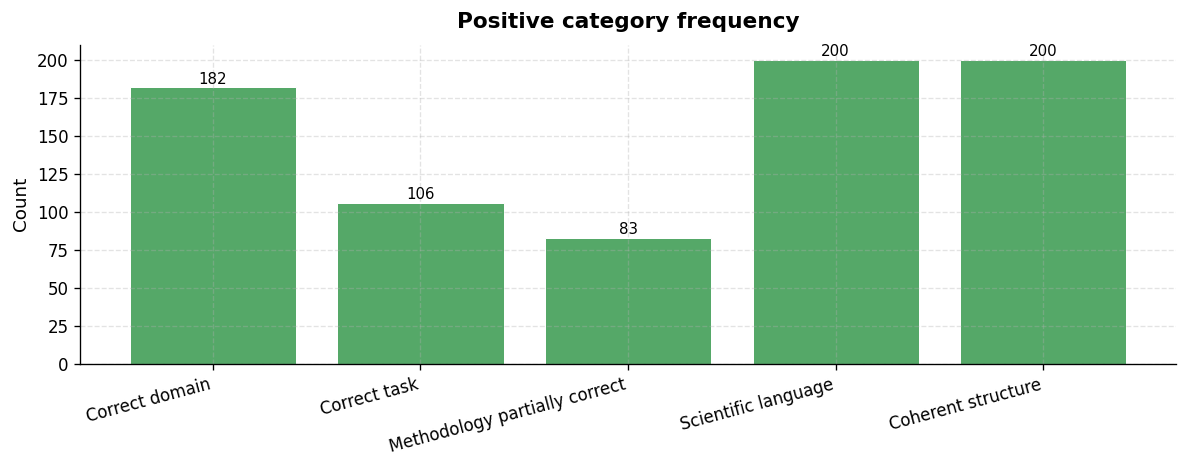

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()